# Part 2. How do two neurons encode shared input?

Two unconnected Morris–Lecar neurons get currents with a known correlation, $c$. Do their firing rates rise and fall together (rate comodulation)? Do their spikes line up in time (synchrony)?

We count spikes in 200 ms windows. The count correlation, $\rho_{200}$, tells us whether the two counts rise and fall together. Either pattern can contribute. The cross-correlogram (CCG) shows the timing in 1 ms steps. Zero lag means spikes in the same bin.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t as student_t

results = Path("results")
sys.path.insert(0, str(Path("scripts").resolve()))
from calibration import evaluate

def load(name):
    with np.load(results / f"{name}.npz") as data:
        return dict(data)

def band(ax, x, replicates, label, color):
    mean = replicates.mean(axis=0)
    half = student_t.ppf(.975, len(replicates)-1) * replicates.std(axis=0, ddof=1) / np.sqrt(len(replicates))
    ax.plot(x, mean, marker=".", color=color, label=label)
    ax.fill_between(x, mean-half, mean+half, color=color, alpha=.15, linewidth=0)

g = load("transfer")
c, lag, targets = g["levels"], g["lags"], g["targets"]
test = slice(int(g["train"]), None)
rho, ccg = g["rho"][:, :, test], g["ccg"][:, :, test] * 1e6  # CCG in Hz²
pred = g["predicted"] * 1e6
colors = ["#467599", "#cf7939", "#458466"]
rate_labels = [f"{v} Hz target" for v in targets]

## 1. Two integrators

The left plots show the two currents and the spikes. The right plot shows three curves from the earlier integrator sweep. At 11.7 Hz, $c=0.2$ gives a count correlation near 0.13. At 3.3 Hz, it takes $c=0.3$ to get about the same result. [All 60 sweep results](results/original_integrator.csv)

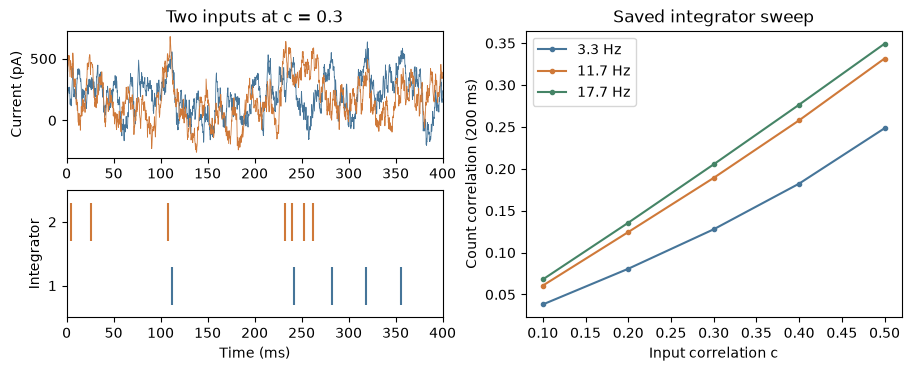

In [2]:
legacy = np.genfromtxt(results / "original_integrator.csv", delimiter=",", names=True)
ex = load("pair_example")
fig = plt.figure(figsize=(9, 3.6), layout="constrained")
grid = fig.add_gridspec(2, 2)
current_ax, raster_ax, old_ax = fig.add_subplot(grid[0, 0]), fig.add_subplot(grid[1, 0]), fig.add_subplot(grid[:, 1])
for i in range(2):
    current_ax.plot(np.arange(2000)/5, ex["input"][i, :2000], lw=.6, color=colors[i])
    start, stop = ex["offsets"][i:i+2]
    times = ex["spikes"][start:stop]
    raster_ax.eventplot(times[times < 400], lineoffsets=i+1, linelengths=.6, color=colors[i])
current_ax.set(xlim=(0,400), ylabel="Current (pA)", title="Two inputs at c = 0.3")
raster_ax.set(xlim=(0,400), ylim=(.5,2.5), yticks=[1,2], xlabel="Time (ms)", ylabel="Integrator")
reference = legacy[np.isclose(legacy["input_c"], .3)]
for color, target in zip(colors, [3,12,20]):
    row = reference[np.argmin(abs(reference["rate_Hz"]-target))]
    dr = legacy[legacy["mean_pA"] == row["mean_pA"]]
    old_ax.plot(dr["input_c"], dr["rho200"], ".-", color=color, label=f'{row["rate_Hz"]:.1f} Hz')
old_ax.set(xlabel="Input correlation c", ylabel="Count correlation (200 ms)", title="Saved integrator sweep")
old_ax.legend()
plt.show()

In the new sweep, we vary $c$ from 0 to 0.5 at three target rates (6, 12 and 20 Hz). We use larger current fluctuations so integrators (I) and detectors (D) can reach similar rates. The table shows the rates they reached. Shaded bands in the plots show 95% confidence intervals.

Rate target    I mean (pA)    D mean (pA)    I rate (Hz)    D rate (Hz)
       6          158.9          362.5           6.13           5.68
      12          200.8          450.9          11.45          12.30
      20          243.9          524.2          19.74          19.84


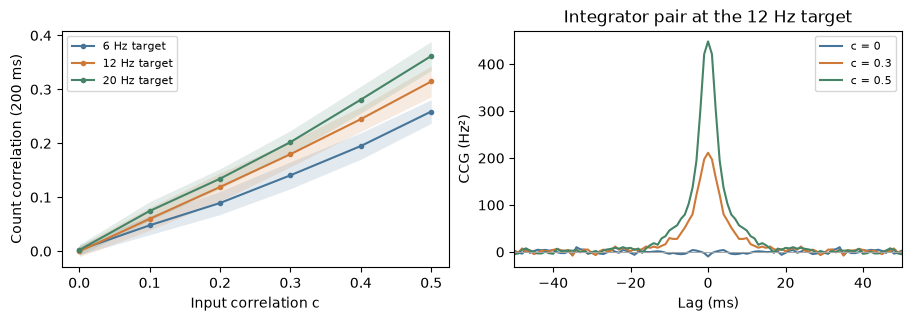

In [3]:
print("Rate target    I mean (pA)    D mean (pA)    I rate (Hz)    D rate (Hz)")
achieved = g["rate"][:, :, test].mean(axis=(1,2))
for i, target in enumerate(targets):
    print(f'{target:8d} {g["means"][0,i]:14.1f} {g["means"][1,i]:14.1f}'
          f' {achieved[i,0]:14.2f} {achieved[i,1]:14.2f}')

fig, ax = plt.subplots(1, 2, figsize=(9, 3.1), layout="constrained")
for r, color in enumerate(colors):
    band(ax[0], c, rho[r,:,:,0,0].T, rate_labels[r], color)
for j, color in zip([0,3,5], colors):
    ax[1].plot(lag, ccg[1,j,:,0].mean(0), color=color, label=f"c = {c[j]:g}")
ax[0].set(xlabel="Input correlation c", ylabel="Count correlation (200 ms)")
ax[1].axhline(0, color=".65", lw=.7)
ax[1].set(xlim=(-50,50), xlabel="Lag (ms)", ylabel="CCG (Hz²)", title="Integrator pair at the 12 Hz target")
for a in ax: a.legend(fontsize=8)
plt.show()

With independent inputs, count correlation is near zero. With shared input, the broad peak shows that the cells tend to fire more around the same time. Faster-firing pairs have higher count correlations at the same $c$.

## 2. Two coincidence detectors

One potassium-current setting changes an integrator into a detector ($\beta_w$ goes from 0 to −21 mV). We test both types with a steady current, then with three short pulses. Only the gap between pulses changes in the right plot.

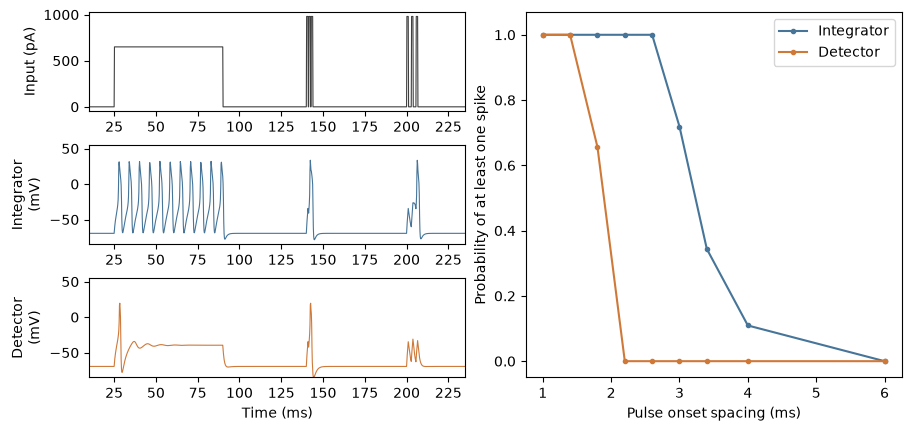

In [4]:
d = load("responses")
fig = plt.figure(figsize=(9, 4.2), layout="constrained")
grid = fig.add_gridspec(3, 2)
left = [fig.add_subplot(grid[i,0]) for i in range(3)]
right = fig.add_subplot(grid[:,1])
left[0].plot(d["t"], d["current"], color=".25", lw=.8)
left[0].set(ylabel="Input (pA)")
for i, name in enumerate(["Integrator", "Detector"]):
    left[i+1].plot(d["t"], d["voltage"][i], lw=.8, color=colors[i])
    left[i+1].set(ylabel=f"{name}\n(mV)", ylim=(-85,55))
    right.plot(d["spacing"], d["probability"][i], ".-", color=colors[i], label=name)
for a in left: a.set_xlim(10,235)
left[-1].set_xlabel("Time (ms)")
right.set(xlabel="Pulse onset spacing (ms)", ylabel="Probability of at least one spike", ylim=(-.05,1.07))
right.legend()
plt.show()

The integrator keeps firing during the steady current. The detector fires at the start and needs closer pulses to fire again.

Next, compare the two pair types at $c=0.3$ and about 12 Hz. The solid curves show the measured CCGs. The dashed curves show the first-order prediction from the average noise signal before a spike in independent-input trials.

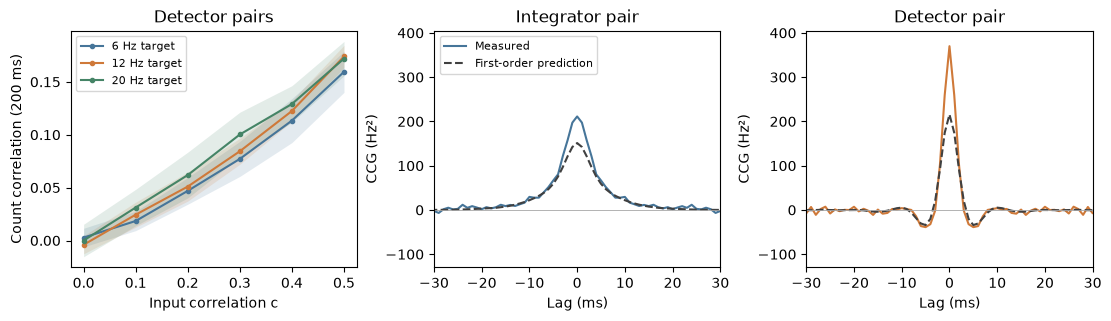

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.1), layout="constrained")
for r, color in enumerate(colors):
    band(ax[0], c, rho[r,:,:,1,0].T, rate_labels[r], color)
ax[0].set(xlabel="Input correlation c", ylabel="Count correlation (200 ms)", title="Detector pairs")
ax[0].legend(fontsize=8)
for k, name in enumerate(["Integrator pair", "Detector pair"]):
    a = ax[k+1]
    a.plot(lag, ccg[1,3,:,k].mean(0), color=colors[k], label="Measured")
    a.plot(lag, pred[1,3,k], "--", color=".25", label="First-order prediction")
    a.axhline(0, color=".65", lw=.6)
    a.set(xlim=(-30,30), ylim=(-130,405), xlabel="Lag (ms)", ylabel="CCG (Hz²)", title=name)
    if k == 0: a.legend(fontsize=8, loc="upper left")
plt.show()

The detectors spike together more often at zero lag. But their 200 ms count correlation is lower (0.084, versus 0.180 for integrators). The dips on either side of the detector peak bring it down.

Does the prediction miss mainly at the peak? We measure count covariance at $c=0.5$, then leave out the bins within 2 ms of zero and measure it again.

In [6]:
weight = np.maximum(200 - abs(lag), 0)
outside_peak = abs(lag) > 2
print("Target Hz    measured    predicted    measured outside    predicted outside")
for r, target in enumerate(targets):
    observed = ccg[r,5,:,1].mean(0) / 1e6
    linear = pred[r,5,1] / 1e6
    print(f"{target:9d} {observed @ weight:11.3f} {linear @ weight:12.3f}"
          f" {(observed*outside_peak) @ weight:19.3f} {(linear*outside_peak) @ weight:20.3f}")

Target Hz    measured    predicted    measured outside    predicted outside
        6       0.171        0.074              -0.001                0.002
       12       0.387        0.186              -0.062               -0.063
       20       0.556        0.276              -0.231               -0.224


At 12 Hz, the measured and predicted values are 0.387 and 0.186 spikes². Without the central peak, they almost match (−0.062 and −0.063).

## 3. Sharing slow changes or brief events

We keep the cells and total input correlation ($c=0.30$) the same. The cells share slow changes, brief events, or some of each. Each cell also gets its own background noise.

We chose how much input to share. The model has no adaptation current.

In [7]:
h = load("hybrid")
print(f'Frozen hybrid setting: beta_w = {h["beta"]:.0f} mV, mean current = {h["mean"]:.1f} pA')
print("Shared input          measured c    input SD (pA)    rate (Hz)    rho200    rho40")
for i, name in enumerate(h["conditions"][:3]):
    a, b = h["rho"][i].mean(0)
    print(f'{name:19s} {h["actual_c"][i].mean():10.3f} {h["input_sd"][i].mean():16.1f}'
          f' {h["rate"][i].mean():12.2f} {a:9.3f} {b:8.3f}')

Frozen hybrid setting: beta_w = -13 mV, mean current = 392.2 pA
Shared input          measured c    input SD (pA)    rate (Hz)    rho200    rho40
Slow shared              0.303             40.0        12.07     0.581    0.426
Events shared            0.308             40.1        12.20     0.020    0.039
Both shared              0.302             40.1        12.11     0.268    0.203


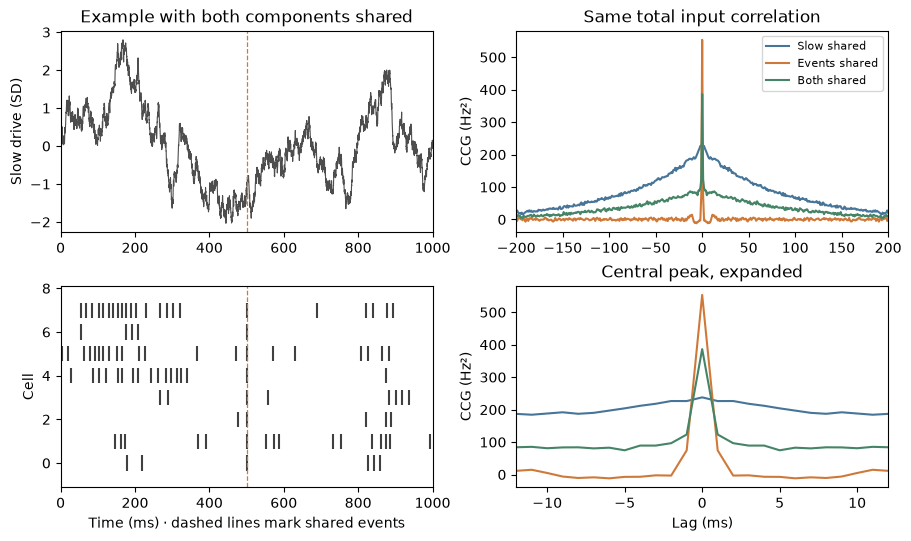

In [8]:
hx = load("hybrid_example")
fig, ax = plt.subplots(2, 2, figsize=(9, 5.3), layout="constrained")
x = np.arange(len(hx["slow"]))/5
ax[0,0].plot(x, hx["slow"], color=".3", lw=.8)
ax[0,0].set(xlim=(0,1000), ylabel="Slow drive (SD)", title="Example with both components shared")
ax[1,0].eventplot([np.flatnonzero(row) for row in hx["raster"]], colors=".25", linelengths=.7)
for a in ax[:,0]:
    for onset in hx["events"]: a.axvline(onset, color=colors[1], lw=.9, ls="--")
ax[1,0].set(xlim=(0,1000), xlabel="Time (ms) · dashed lines mark shared events", ylabel="Cell")
for i, name in enumerate(h["conditions"][:3]):
    curve = h["ccg"][i].mean(0)*1e6
    for a in ax[:,1]: a.plot(lag, curve, label=name, color=colors[i])
ax[0,1].set(xlim=(-200,200), ylabel="CCG (Hz²)", title="Same total input correlation")
ax[1,1].set(xlim=(-12,12), xlabel="Lag (ms)", ylabel="CCG (Hz²)", title="Central peak, expanded")
ax[0,1].legend(fontsize=8)
plt.show()

On the left, we group the slow input from low to high and measure firing rate in each group. We skip the 15 ms after each event.

On the right, we count pairs that spike in the same 1 ms bin after a shared event. We check the same times in runs where each cell gets its own events.

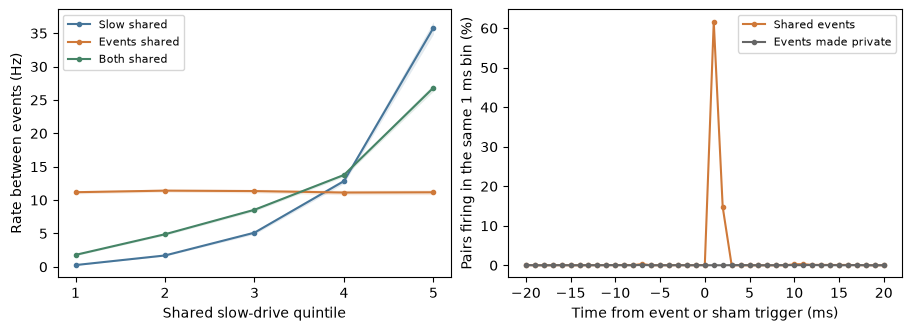

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2), layout="constrained")
for i, name in enumerate(h["conditions"][:3]):
    per_seed = h["by_slow"][i] / h["exposure"][i]
    band(ax[0], np.arange(1,6), per_seed, name, colors[i])
for i, name, color in [(2,"Shared events",colors[1]), (3,"Events made private",".4")]:
    frac = h["event_pairs"][i].sum(0) / h["n_events"][i].sum()
    ax[1].plot(np.arange(-20,21), 100*frac, ".-", color=color, label=name)
ax[0].set(xlabel="Shared slow-drive quintile", xticks=range(1,6), ylabel="Rate between events (Hz)")
ax[1].set(xlabel="Time from event or sham trigger (ms)", ylabel="Pairs firing in the same 1 ms bin (%)")
for a in ax: a.legend(fontsize=8)
plt.show()

When both signals are shared, firing rises from 2 to 27 Hz as the slow input rises. One millisecond after a shared event, 62% of pairs spike together. With independent events, fewer than 0.1% do at the same times.

Sharing only slow changes gives a 200 ms count correlation of 0.58. Sharing only brief events gives 0.02, even though $c$ and the mean firing rate barely change.

## 4. One integrator and one detector

Can two cells of the same type tell us how to read a mixed pair? We compare all three pair types using both 200 ms and 40 ms count windows. In the mixed pair, the peak at −1 ms means the detector tends to spike first.

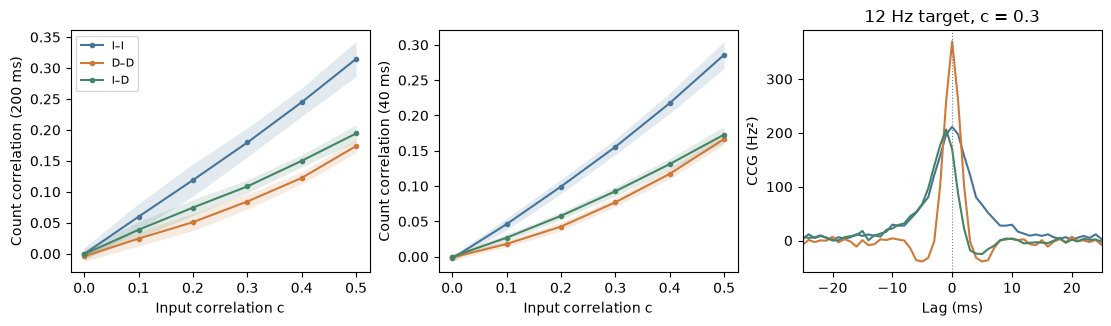

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.15), layout="constrained")
for k, name in enumerate(g["pairs"]):
    for w, window in enumerate(g["windows"]):
        band(ax[w], c, rho[1,:,:,k,w].T, name, colors[k])
        ax[w].set(xlabel="Input correlation c", ylabel=f"Count correlation ({window} ms)")
    ax[2].plot(lag, ccg[1,3,:,k].mean(0), label=name, color=colors[k])
ax[2].axvline(0, ls=":", lw=.8, color=".5")
ax[2].set(xlim=(-25,25), xlabel="Lag (ms)", ylabel="CCG (Hz²)", title="12 Hz target, c = 0.3")
ax[0].legend(fontsize=8)
plt.show()

At each rate and window, we fit one line through zero for integrator pairs and one for detector pairs. On fresh runs, we use each line to estimate $c$ from count correlation. The dotted line shows a perfect estimate.

Bias is the average error, with a minus sign for estimates that are too low. MAE is the average error size in either direction.

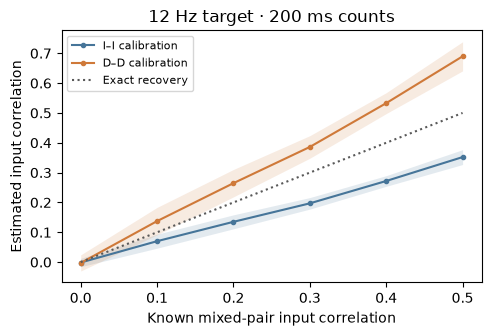

Window    Fit → test        Bias        MAE       95% interval for MAE
 200 ms   I–I → I–I      +0.025      0.052       [0.037, 0.085]
 200 ms   I–I → I–D      -0.079      0.084       [0.062, 0.103]
 200 ms   D–D → D–D      +0.031      0.080       [0.062, 0.120]
 200 ms   D–D → I–D      +0.094      0.108       [0.069, 0.167]
  40 ms   I–I → I–I      +0.005      0.032       [0.026, 0.041]
  40 ms   I–I → I–D      -0.096      0.098       [0.086, 0.108]
  40 ms   D–D → D–D      +0.001      0.046       [0.041, 0.056]
  40 ms   D–D → I–D      +0.038      0.050       [0.038, 0.070]


In [11]:
fit, scores, bounds = evaluate(g["rho"], c, int(g["train"]))
fig, ax = plt.subplots(figsize=(4.8, 3.25), layout="constrained")
for k, name in enumerate(["I–I calibration", "D–D calibration"]):
    estimates = rho[1,:,:,2,0].T / fit[1,k,0]
    band(ax, c, estimates, name, colors[k])
ax.plot(c,c,":",color=".35",label="Exact recovery")
ax.set(xlabel="Known mixed-pair input correlation", ylabel="Estimated input correlation",
       title="12 Hz target · 200 ms counts")
ax.legend(fontsize=8)
plt.show()

print("Window    Fit → test        Bias        MAE       95% interval for MAE")
for w, window in enumerate(g["windows"]):
    for k, label in enumerate(["I–I → I–I", "I–I → I–D", "D–D → D–D", "D–D → I–D"]):
        bias, mae = scores[k,w]
        lo, hi = bounds[:,k,w,1]
        print(f"{window:4d} ms   {label:12s} {bias:+8.3f} {mae:10.3f}       [{lo:.3f}, {hi:.3f}]")

With 200 ms counts, the integrator fit estimates $c$ about 0.08 too low for the mixed pair. The detector fit estimates it about 0.09 too high. With 40 ms counts, the detector fit is closer (0.04 too high). Julian can test this with the recordings.

### Running the notebook

Run the cells to use the saved results. To repeat the simulations, install `requirements.txt` and run `python scripts/run.py --workers 4` from this folder. We used Python 3.12, NEURON 9.0.2 and a C++ compiler.